# 09 – LASSO and an Event Study of Retirements

**Objective:** use two econometric tools to understand the model better. LASSO asks which variables the model really needs. An event study asks what happens to a player after retiring from a match.

**Key results**
- **LASSO doesn't predict better:** its best log loss on validation is 0.5849, the same as the current model.
- **It makes the model easier to read:** `d_serve_slow`, with a puzzling coefficient of −0.639, goes to zero, and so do the ATP ranking variables once Elo is included.
- **Players win less after retiring:** across 8,032 retirements, win probability is 5.49 points lower in the next match than after an ordinary loss (95% interval: −6.71 to −4.22), and still 3.00 points lower across matches +4 to +10.
- **The pre-trend check caught a flawed comparison:** the first version showed a jump of −8.24 before the event, which falls to −0.54 once the comparison is balanced.
- **This is unlikely to improve predictions much:** the affected matches are few, so even perfect use would gain only about 0.0002 in log loss.

**Data:** this notebook only reads matches up to 2021, so the 2022–2026 test from notebook 08 stays untouched. Nothing here changes the final model.

In [1]:
import sqlite3
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "../src")
from tennis_data import load_all_matches
from tennis_domain_features import DOMAIN_GROUPS
from tennis_elo import run_elo
from tennis_event_study import (
    K, build_windows, estimate_path, player_match_table, pooled_effect, reach_share, time_away,
    walkover_losses_by_player,
)
from tennis_features import FEATURE_GROUPS
from tennis_models import (
    INTERACTIONS, add_interactions, fit_both_views, lasso_model, logistic_model, score, walk_forward,
)

CHART_COLOR = "#2a78d6"
TEXT_COLOR = "#52514e"
GRID_COLOR = "#e4e3df"
REFERENCE_COLOR = "#8a8981"
LAST_YEAR = 2021

conn = sqlite3.connect(Path("../data/processed/tennis.db"))
data = pd.read_sql_query(f"SELECT * FROM final_features WHERE tourney_level <> 'D' AND year <= {LAST_YEAR}", conn)
data = add_interactions(data)

ORDER = ["Elo", "Ranking", "Serve and return", "Form", "Fatigue and fitness", "Experience",
         "Style and age", "Head to head", "Draw", "Home"]
FINAL_COLUMNS = (
    [c for group in ORDER for c in FEATURE_GROUPS[group]]
    + list(INTERACTIONS) + DOMAIN_GROUPS["Tournament history"]
)
validation = data["year"].between(2015, 2021)
train = data[data["year"].between(2005, 2021)]
print(f"Latest year loaded: {data['year'].max()}. Model columns: {len(FINAL_COLUMNS)}. Validation matches: {validation.sum():,}")

Latest year loaded: 2021. Model columns: 60. Validation matches: 17,126


# Part A: LASSO

## 1. What LASSO changes

Our model is a logistic regression, so it has one coefficient (β) for each of its 60 columns. A penalty stops those coefficients from growing too large and fitting noise.

| | Penalty | Effect on coefficients |
|---|---|---|
| **Current model** | β² | Shrinks them towards zero |
| **LASSO** | \|β\| | Shrinks them, and can set them to exactly zero |

So LASSO also chooses variables. In scikit-learn, `C` is the inverse of the usual penalty λ: **a smaller `C` means a stronger penalty**.

## 2. Does it predict better?

Each year from 2015 to 2021 is predicted by a model trained on earlier years only, as in notebook 06.

In [2]:
scores = [{"model": "Current model", "C": 0.1, **score(walk_forward(data, FINAL_COLUMNS, logistic_model)[validation]),
           "variables_kept": len(FINAL_COLUMNS)}]


def coefficients(model):
    return pd.Series(model.steps[-1][1].coef_[0], index=FINAL_COLUMNS)


for C in [0.1, 0.03, 0.01, 0.003, 0.001, 0.0003, 0.0001]:
    predictions = walk_forward(data, FINAL_COLUMNS, lambda: lasso_model(C))
    kept = int((coefficients(fit_both_views(lasso_model(C), train[FINAL_COLUMNS])) != 0).sum())
    scores.append({"model": "LASSO", "C": C, **score(predictions[validation]), "variables_kept": kept})
pd.DataFrame(scores)

,model,C,accuracy_pct,log_loss,variables_kept
0,Current model,0.1000,68.38,0.5849,60
1,LASSO,0.1000,68.36,0.5849,56
2,LASSO,0.0300,68.46,0.5850,54
3,LASSO,0.0100,68.43,0.5851,45
4,LASSO,0.0030,68.36,0.5864,28
5,LASSO,0.0010,68.04,0.5925,14
6,LASSO,0.0003,67.58,0.6023,3
7,LASSO,0.0001,67.56,0.6447,1


**Finding:** LASSO gives no real gain. Its best log loss, 0.5849, equals the current model's, and accuracy differences of a few hundredths of a point are too small to matter. The simpler versions are more interesting: 28 variables reach 68.36% accuracy with a log loss of 0.5864, while 14 variables fall to 68.04% and 0.5925.

## 3. Which variables does it keep?

These coefficients come from a model trained on 2005–2021. The variables are standardised, so a coefficient is the change in log-odds for one standard deviation.

We use `C = 0.01`, which keeps the score close to the best with a clearly stronger penalty.

In [3]:
SMALL_C = 0.01
current = coefficients(fit_both_views(logistic_model(), train[FINAL_COLUMNS]))
lasso = coefficients(fit_both_views(lasso_model(SMALL_C), train[FINAL_COLUMNS]))
comparison = pd.DataFrame({"current_model": current, "lasso": lasso})
comparison.reindex(comparison["lasso"].abs().sort_values(ascending=False).index).head(12).round(3)

,current_model,lasso
d_elo_overall,0.540,0.539
d_elo_combined,0.331,0.313
d_log_tour_career,0.270,0.269
d_log_career,-0.273,-0.254
d_log_surface_career,0.238,0.223
d_age,-0.193,-0.186
d_serve_fast,0.286,0.179
d_elo_x_slam,0.156,0.164
d_win_last_20,-0.183,-0.140
d_matches_30,0.102,0.094


In [4]:
removed = comparison[comparison["lasso"] == 0].sort_values("current_model", key=np.abs, ascending=False)
print(f"Set to exactly zero: {len(removed)} of {len(comparison)}")
removed.round(3)

Set to exactly zero: 15 of 60


,current_model,lasso
d_serve_slow,-0.639,0.0
d_serve_adj,0.397,0.0
d_return_slow,-0.331,0.0
d_serve_x_court_aces,0.126,0.0
d_matches_7,-0.050,0.0
d_minutes_14,-0.048,0.0
d_elo_surface,-0.039,0.0
d_log_points,0.037,0.0
d_elo_x_best_of_5,0.016,0.0
d_ace_rate,0.011,0.0


**Finding:**
- **The puzzling coefficient disappears.** `d_serve_slow` was −0.639, which seemed to say that better servers win less. LASSO sets it to zero, which suggests the sign came mostly from overlap with correlated variables such as Elo and other serve measures. A coefficient here isn't the effect of that variable alone.
- **Elo replaces the ATP ranking.** `d_log_rank` and `d_log_points` both go to zero, while the two Elo variables remain the largest.
- **Experience depends on the level.** More main-tour matches help (+0.269), while the total number of matches has a negative sign (−0.254).
- **Recent form stays negative.** `d_win_last_20` is −0.140 after accounting for Elo, which already contains those wins. It doesn't mean that winning is harmful.

## 4. How stable is the selection?

If we drew slightly different matches, would LASSO choose the same variables? The **bootstrap** resamples the training matches with replacement and fits LASSO again each time.

In [5]:
ROUNDS = 30
rng = np.random.default_rng(0)
kept_count = pd.Series(0, index=FINAL_COLUMNS)
for _ in range(ROUNDS):
    sample = train.iloc[rng.integers(0, len(train), len(train))]
    kept_count += (coefficients(fit_both_views(lasso_model(SMALL_C), sample[FINAL_COLUMNS])) != 0).astype(int)

stability = (100 * kept_count / ROUNDS).round(0).astype(int).rename("kept_pct").sort_values(ascending=False)
print(f"Always kept: {(kept_count == ROUNDS).sum()}, sometimes kept: {((kept_count > 0) & (kept_count < ROUNDS)).sum()}, "
      f"never kept: {(kept_count == 0).sum()}")
print("Never kept:", list(kept_count.index[kept_count == 0]))
stability[["d_elo_overall", "d_age", "d_home", "d_return_adj", "d_recent_problem", "d_elo_surface", "d_serve_slow", "d_serve_adj"]].to_frame()

Always kept: 22, sometimes kept: 36, never kept: 2
Never kept: ['d_log_rank', 'd_return_slow']


,kept_pct
d_elo_overall,100
d_age,100
d_home,100
d_return_adj,80
d_recent_problem,40
d_elo_surface,23
d_serve_slow,17
d_serve_adj,10


**Finding:** 22 variables survive every round, 36 only some of the time, and 2 never do. **A variable set to zero isn't necessarily useless:** among correlated variables, LASSO often keeps one and drops the others, and the choice can change with the sample. Thirty rounds give a rough guide, not a precise estimate.

**Decision:** keep the current model for prediction, because LASSO doesn't beat it. LASSO is useful as a way of explaining the model. The 2022–2026 test has already been used, so it wouldn't be a clean test of a new model anyway.

# Part B: Event study of retirements

## 5. The question and the design

**Question:** how does a player perform in the matches after retiring from one?

Simply comparing before and after would be misleading, because a player's sequence of matches has its own pattern. Reaching a later round requires a win, so the match before a loss is often a win. We therefore compare each retirement with **ordinary losses**, which makes this a difference-in-differences across event time.

| Choice | Decision |
|---|---|
| **Event** | A retirement during a match, 2005–2021, at any level |
| **Comparison** | Up to 5 ordinary losses by the same player at the same level, nearest in time |
| **Window** | 10 of the player's matches on each side, with no other retirement or walkover loss |
| **Outcome** | Won (0 or 1) minus the win probability expected from Elo |
| **Player's Elo** | Frozen before the window, so the retirement can't change the yardstick |
| **Opponent's Elo** | Current at each match, so easier or harder opponents are accounted for |
| **Baseline** | The average of matches −10 to −6 |
| **Uncertainty** | Bootstrap of whole players, because a player's matches are not independent |
| **Measures fixed before the results** | Match +1, the average of +1 to +3, and the pre-trend check on −5 to −1 |

Match 0 is a loss in both groups by construction, so it is left out.

In [6]:
matches = load_all_matches("../data/raw")
matches = matches[matches["year"] <= LAST_YEAR].reset_index(drop=True)
ratings = run_elo(matches, k=28, inactivity=0.3, new_player_boost=1.0)
long = player_match_table(matches, ratings)
walkover_days = walkover_losses_by_player(matches)
print(f"{len(matches):,} matches, up to {matches['year'].max()}")

721,338 matches, up to 2021


## 6. First attempt: the pre-trend check fails

Before the event, the two groups should move together. If they don't, the comparison can't be trusted. The first version matched only on player and level.

In [7]:
windows_first, events_first = build_windows(long, walkover_days, match_position=False)
table_first, draws_first = estimate_path(windows_first)
print(f"Retirements: {(events_first['group'] == 1).sum():,}")
table_first[table_first["k"].between(-5, -1)].round(2)

Retirements: 8,156


,k,retired,ordinary_loss,effect,low_95,high_95
5,-5,0.71,-0.23,0.94,-0.27,2.18
6,-4,1.42,0.13,1.29,0.16,2.42
7,-3,1.14,0.61,0.53,-0.65,1.81
8,-2,2.35,2.54,-0.19,-1.22,0.98
9,-1,-0.42,7.82,-8.24,-9.38,-6.99


**Finding:** matches −5 to −2 look flat, but match −1 jumps to −8.24, so the comparison isn't balanced.

The likely reason is the structure of a tournament. Before a loss in a player's first match of an event, the previous match is usually the loss that ended the last event. Before a loss later in an event, the previous match is always a win. So a difference in that mix changes match −1 sharply, even if nothing happened to the player.

## 7. The corrected comparison

Ordinary losses must now also have the same place in a tournament as the retirement: a player's first match there, or a later one.

In [8]:
windows, events = build_windows(long, walkover_days, match_position=True)
table, draws = estimate_path(windows)
print(f"Retirements: {(events['group'] == 1).sum():,}, ordinary losses: {(events['group'] == 0).sum():,}, "
      f"players: {windows.loc[windows['group'] == 1, 'player'].nunique():,}")
table.round(2)

Retirements: 8,032, ordinary losses: 38,019, players: 2,688


,k,retired,ordinary_loss,effect,low_95,high_95
0,-10,0.16,-0.30,0.46,-0.54,1.39
1,-9,-0.24,-0.43,0.19,-0.84,1.16
2,-8,-0.10,0.00,-0.11,-1.02,0.85
3,-7,0.04,0.67,-0.63,-1.57,0.33
4,-6,0.15,0.06,0.09,-0.82,1.04
5,-5,0.80,-0.26,1.05,-0.08,2.26
6,-4,1.32,0.02,1.30,0.09,2.37
7,-3,1.09,0.27,0.82,-0.48,2.14
8,-2,2.41,3.48,-1.07,-2.23,0.16
9,-1,-0.45,0.10,-0.54,-1.29,0.26


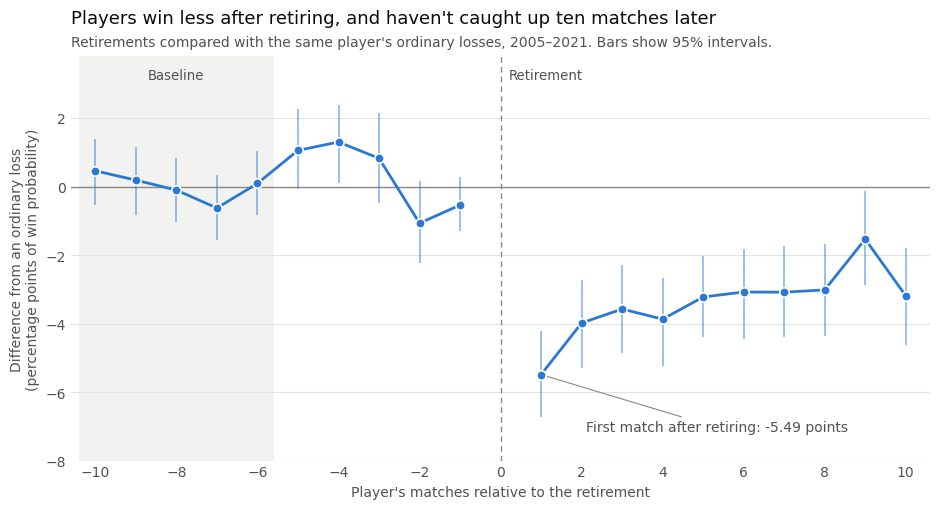

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 5.2))
ax.axvspan(-10.4, -5.6, color=GRID_COLOR, alpha=0.45, linewidth=0, zorder=0)
ax.axhline(0, color=REFERENCE_COLOR, linewidth=1, zorder=1)
ax.axvline(0, color=REFERENCE_COLOR, linewidth=1, linestyle=(0, (4, 3)), zorder=1)
for part in [table[table["k"] < 0], table[table["k"] > 0]]:
    ax.plot(part["k"], part["effect"], color=CHART_COLOR, linewidth=2, zorder=3)
ax.vlines(table["k"], table["low_95"], table["high_95"], color=CHART_COLOR, linewidth=1.2, alpha=0.55, zorder=2)
ax.scatter(table["k"], table["effect"], s=46, color=CHART_COLOR, edgecolor="white", linewidth=1.2, zorder=4)

first_match = table[table["k"] == 1].iloc[0]
ax.annotate(f"First match after retiring: {first_match['effect']:.2f} points", xy=(1, first_match["effect"]),
            xytext=(2.1, -7.15), color=TEXT_COLOR, fontsize=10,
            arrowprops=dict(arrowstyle="-", color=REFERENCE_COLOR, linewidth=0.8))
ax.text(-8, 3.25, "Baseline", color=TEXT_COLOR, fontsize=9.5, ha="center", va="center")
ax.text(0.2, 3.25, "Retirement", color=TEXT_COLOR, fontsize=9.5, ha="left", va="center")

ax.set_xlim(-10.6, 10.6)
ax.set_ylim(-8, 3.8)
ax.set_xticks(range(-10, 11, 2))
ax.set_yticks(range(-8, 4, 2))
ax.set_xlabel("Player's matches relative to the retirement", color=TEXT_COLOR)
ax.set_ylabel("Difference from an ordinary loss\n(percentage points of win probability)", color=TEXT_COLOR)
ax.tick_params(colors=TEXT_COLOR, length=0)
ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax.set_title("Players win less after retiring, and haven't caught up ten matches later",
             loc="left", fontsize=13, color="#0b0b0b", pad=24)
ax.text(0, 1.025, "Retirements compared with the same player's ordinary losses, 2005–2021. Bars show 95% intervals.",
        transform=ax.transAxes, color=TEXT_COLOR, fontsize=10)
fig.tight_layout()
plt.show()

## 8. The measures fixed in advance

In [10]:
measures = {"Pre-trend, matches −5 to −1": range(-5, 0), "Match +1": [1], "Matches +1 to +3": [1, 2, 3],
            "Matches +4 to +10": range(4, 11)}
pd.DataFrame([{"measure": name, **pooled_effect(table, draws, keys)} for name, keys in measures.items()]).round(2)

,measure,effect,low_95,high_95
0,"Pre-trend, matches −5 to −1",0.31,-0.39,1.03
1,Match +1,-5.49,-6.71,-4.22
2,Matches +1 to +3,-4.35,-5.26,-3.50
3,Matches +4 to +10,-3.00,-3.80,-2.25


**Finding:** the pre-trend is now close to zero (+0.31), and its interval includes zero. Match −1 falls from −8.24 to −0.54. One earlier match, −4, has an interval just above zero (+1.30), which isn't surprising among ten pre-event matches.

After a retirement, the player wins 5.49 points less than after an ordinary loss in the next match. A player at 50% would be at about 44.5%. The gap narrows slowly and is still 3.00 points across matches +4 to +10. The balancing changed this result only a little: match +1 was −6.05 in the first version.

## 9. Time away

A retirement can also cost time. Only events up to 2020 are used here, so everyone has at least a year in which to return.

In [11]:
time_away(events).round(1)

,event,median_days,back_in_14d_pct,back_in_30d_pct,back_in_90d_pct,back_in_365d_pct
0,Retirement,14.0,52.4,72.9,90.5,97.5
1,Ordinary loss,7.0,72.4,86.5,96.5,99.1


**Finding:** the median wait for the next match doubles, from 7 to 14 days. Within 14 days, 52.4% of players are back after a retirement, against 72.4% after an ordinary loss. After a year, 2.5% still haven't returned, against 0.9%.

## 10. Does it differ by level?

**This check is exploratory.** The first table splits by the level of the match, and the second by the player's ranking at the time of the retirement.

In [12]:
rows = []
for tier in ["main", "challenger", "qualifying", "futures"]:
    subset = windows[windows["tier"] == tier]
    level_table, level_draws = estimate_path(subset, rounds=500, seed=1)
    rows.append({"level": tier, "retirements": subset.loc[subset["group"] == 1, "event"].nunique(),
                 **pooled_effect(level_table, level_draws, [1, 2, 3])})
pd.DataFrame(rows).round(2)

,level,retirements,effect,low_95,high_95
0,main,863,-3.68,-6.42,-1.03
1,challenger,1486,-3.41,-5.54,-1.37
2,qualifying,735,-4.16,-6.66,-1.75
3,futures,4948,-4.77,-5.84,-3.53


In [13]:
rows = []
for label, low, high in [("1–50", 1, 50), ("51–200", 51, 200), ("201+", 201, 100_000)]:
    subset = windows[windows["event_rank"].between(low, high)]
    band_table, band_draws = estimate_path(subset, rounds=500, seed=2)
    rows.append({"ranking": label, "retirements": subset.loc[subset["group"] == 1, "event"].nunique(),
                 **pooled_effect(band_table, band_draws, [1, 2, 3])})
pd.DataFrame(rows).round(2)

,ranking,retirements,effect,low_95,high_95
0,1–50,416,-3.21,-6.93,0.21
1,51–200,1390,-6.12,-7.77,-4.02
2,201+,5984,-4.27,-5.21,-3.27


**Finding:** the intervals overlap heavily, so **we can't say that one level suffers more than another**. The group with the highest ranking has the smallest sample, and its interval includes zero.

## 11. Why doesn't this help the model more?

The event study freezes a player's Elo, but the model's Elo keeps updating. So we repeat the comparison with **up-to-date** Elo, on all levels and on the main tour.

In [14]:
baseline_positions = [K.index(k) for k in range(-10, -5)]


def live_elo_effects(subset):
    live_table, live_draws = estimate_path(subset.assign(y=subset["live"]))
    shift = live_table["effect"].to_numpy()[baseline_positions].mean()
    live_table["effect"] -= shift
    live_draws = live_draws - live_draws[:, baseline_positions].mean(1, keepdims=True)
    return live_table, live_draws


rows = []
for name, subset in [("All levels", windows), ("Main tour", windows[windows["tier"] == "main"])]:
    live_table, live_draws = live_elo_effects(subset)
    for measure, keys in measures.items():
        rows.append({"sample": name, "measure": measure, **pooled_effect(live_table, live_draws, keys)})
pd.DataFrame(rows).round(2)

,sample,measure,effect,low_95,high_95
0,All levels,"Pre-trend, matches −5 to −1",0.25,-0.45,0.95
1,All levels,Match +1,-5.29,-6.55,-3.99
2,All levels,Matches +1 to +3,-3.97,-4.88,-3.12
3,All levels,Matches +4 to +10,-2.06,-2.83,-1.30
4,Main tour,"Pre-trend, matches −5 to −1",1.69,-0.70,4.04
5,Main tour,Match +1,-5.58,-9.18,-2.22
6,Main tour,Matches +1 to +3,-3.41,-6.00,-0.94
7,Main tour,Matches +4 to +10,-1.94,-4.15,0.31


**Finding:** up-to-date Elo doesn't absorb the immediate drop. Match +1 is −5.29, close to −5.49 with frozen Elo. This makes sense: both groups have just lost, so Elo falls in a similar way for both. Later it catches up partly, with matches +4 to +10 at −2.06 rather than −3.00. The main-tour estimates are similar, but less precise.

**How much could a perfect signal gain?** If a probability is wrong by δ near 50%, correcting it improves that match's log loss by about δ² / (2 × 0.25). We apply this to the main-tour matches affected on the validation years, using the estimate for matches +1 to +3.

In [15]:
recent = long.groupby("player")["retired"].transform(lambda s: s.shift(1).rolling(3, min_periods=1).max()).fillna(0) > 0
period = long["tier"].eq("main") & long["year"].between(2015, 2021)
share_of_player_matches = recent[period].mean()
share_of_matches = 2 * share_of_player_matches
delta = 0.0368
print(f"Player-matches within 3 matches of a retirement: {100 * share_of_player_matches:.1f}%")
print(f"Approximate share of matches affected: {100 * share_of_matches:.1f}%")
print(f"Largest likely gain in overall log loss: {share_of_matches * delta ** 2 / (2 * 0.25):.5f}")

Player-matches within 3 matches of a retirement: 4.2%
Approximate share of matches affected: 8.4%
Largest likely gain in overall log loss: 0.00023


**Finding:** the main reason looks like rarity. About 8% of matches involve a player within three matches of a retirement, and the drop is only a few points. Even perfect use would improve overall log loss by about 0.0002, a rough estimate that is hard to tell apart from noise. The model also already has `d_recent_problem`, and LASSO sets it to zero.

**Not tested:** whether bookmakers price this drop. Our odds start in 2022, inside the test period, so checking this properly would need matches played after June 2026.

## 12. Limits

- **This isn't proof of a causal effect of injury.** Flat pre-trends support the comparison, but parallel trends remain an assumption. A decline that doesn't yet show in results could explain both the retirement and what follows.
- **A retirement isn't the same as an injury.** We can't see players who play on while hurt, or those who withdraw before a match. Some retirements have other causes.
- **Attrition.** Fewer retiring players reach the later matches, as the table below shows. If those who disappear were doing worse, the true effect could be larger.
- **The position match was added after seeing the first results.** It was prompted by the failed pre-trend check, and both versions are reported above.

In [16]:
reach_share(windows, events).round(1)

k,1,5,10
group,,,
Ordinary loss,99.1,97.5,96.1
Retirement,97.7,94.0,91.0


## 13. Conclusions

| Question | Answer |
|---|---|
| Does LASSO predict better than the current model? | No: both reach a log loss of 0.5849 |
| Does LASSO help explain the model? | Yes: Elo replaces the ranking, and the puzzling serve coefficient disappears |
| Do players win less after retiring? | Yes: 5.49 points less in the next match, and 3.00 points less across matches +4 to +10 |
| Is this proof that injuries cause the drop? | No: retirements only approximate injuries, and parallel trends can't be proven |
| Does it differ by level? | We can't tell: the intervals overlap heavily |
| Should the final model change? | No: the possible gain is tiny, and the test period has already been used |

**Main lesson:** explaining and predicting are different goals. A clear, sizeable effect can still add almost nothing to predictions when it affects few matches. The opposite also holds: a model can predict well while its individual coefficients are hard to interpret.